# 04 — Evaluation & Interpretability
**Ames Housing Dataset**

Goal: understand **how good** the final model (Voting Lasso + XGBoost) is, **where it fails**, and **why it predicts what it predicts**.

1. Honest predictions for every training house (out-of-fold)
2. Metrics in dollars, not only in log scale
3. Error analysis: by price range, by sale type, worst cases
4. Interpretability with SHAP: global importance, feature effects, individual explanations

In [1]:
import sys
sys.path.append('..')

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, cross_val_predict

from src.explain import ensemble_shap, group_by_original_feature
from src.models import make_final_model
from src.preprocessing import remove_outliers

warnings.filterwarnings('ignore')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 120})

train = remove_outliers(pd.read_csv('../data/train.csv'))
y = np.log1p(train.pop('SalePrice'))
X = train

## 1. Out-of-fold predictions
To evaluate honestly we need predictions for houses the model **has not seen**. `cross_val_predict` splits the data into 5 folds and predicts each fold with a model trained on the other 4. Result: one honest prediction for each of the 1,458 houses (same folds as in `03_modeling`).

In [2]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
oof_log = cross_val_predict(make_final_model(), X, y, cv=cv)

df = X[['Id', 'Neighborhood', 'SaleCondition', 'OverallQual', 'GrLivArea']].copy()
df['actual'] = np.expm1(y)
df['predicted'] = np.expm1(oof_log)
df['error'] = df['predicted'] - df['actual']
df['pct_error'] = df['error'] / df['actual']
df.head()

,Id,Neighborhood,SaleCondition,OverallQual,GrLivArea,actual,predicted,error,pct_error
0,1,CollgCr,Normal,7,1710,208500.0,202605.502932,-5894.497068,-0.028271
1,2,Veenker,Normal,6,1262,181500.0,182011.653214,511.653214,0.002819
2,3,CollgCr,Normal,7,1786,223500.0,214242.039384,-9257.960616,-0.041423
3,4,Crawfor,Abnorml,7,1717,140000.0,179684.802108,39684.802108,0.283463
4,5,NoRidge,Normal,8,2198,250000.0,294211.134956,44211.134956,0.176845


## 2. Metrics

In [3]:
abs_pct = df['pct_error'].abs()
metrics = pd.Series({
    'RMSE (log scale, Kaggle metric)': np.sqrt(np.mean((oof_log - y) ** 2)),
    'R² (USD)': r2_score(df['actual'], df['predicted']),
    'MAE (USD)': df['error'].abs().mean(),
    'Median absolute error (USD)': df['error'].abs().median(),
    'MAPE (mean % error)': abs_pct.mean(),
    'Houses within ±10%': (abs_pct <= 0.10).mean(),
    'Houses within ±20%': (abs_pct <= 0.20).mean(),
})
fmt = ['{:.4f}', '{:.3f}', '${:,.0f}', '${:,.0f}', '{:.1%}', '{:.1%}', '{:.1%}']
metrics.to_frame('value').assign(value=[f.format(v) for f, v in zip(fmt, metrics)])

,value
"RMSE (log scale, Kaggle metric)",0.1072
R² (USD),0.936
MAE (USD),"$12,937"
Median absolute error (USD),"$8,788"
MAPE (mean % error),7.5%
Houses within ±10%,77.0%
Houses within ±20%,95.2%


How to read them:
- **R² ≈ 0.94**: the model explains ~94% of the variation in prices between houses.
- **Median error ≈ $8.8k**: for a typical house the prediction is off by less than $9k. The mean (MAE ≈ $13k) is higher because a few large errors pull it up.
- **MAPE ≈ 7.5%**, and **77%** of houses are predicted within ±10% of their real price, **95%** within ±20%.

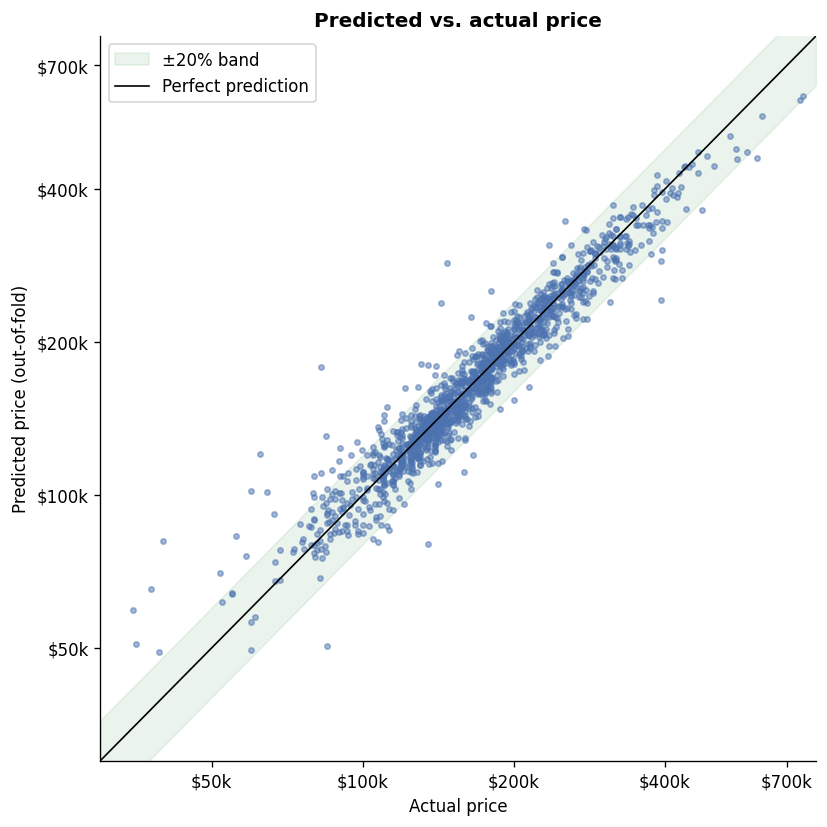

In [4]:
fig, ax = plt.subplots(figsize=(7, 7))
lim = [30_000, 800_000]
ax.fill_between(lim, [l * 0.8 for l in lim], [l * 1.2 for l in lim], color='#55A868', alpha=0.12, label='±20% band')
ax.plot(lim, lim, color='black', linewidth=1, label='Perfect prediction')
ax.scatter(df['actual'], df['predicted'], s=10, alpha=0.5, color='#4C72B0')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(lim); ax.set_ylim(lim)
ticks = [50_000, 100_000, 200_000, 400_000, 700_000]
ax.set_xticks(ticks, [f'${t/1000:.0f}k' for t in ticks]); ax.set_yticks(ticks, [f'${t/1000:.0f}k' for t in ticks])
ax.minorticks_off()
ax.set_xlabel('Actual price'); ax.set_ylabel('Predicted price (out-of-fold)')
ax.set_title('Predicted vs. actual price', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Error analysis

### 3.1 By price range
Houses are split into 5 equal-size groups (quintiles) by actual price.
- **Mean absolute % error**: how big the errors are.
- **Mean signed % error (bias)**: whether the model systematically over- (+) or under- (−) predicts.

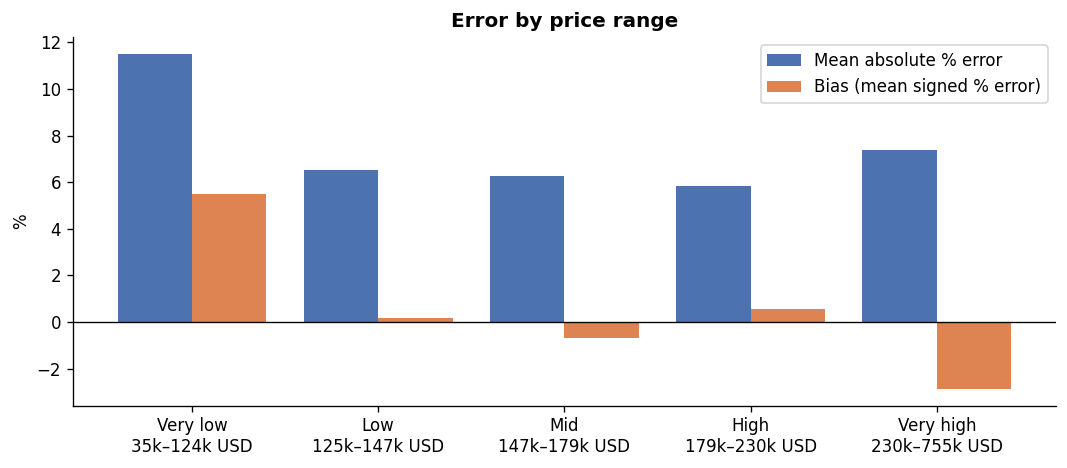

,houses,price_from,price_to,abs_pct_error,bias
price_range,,,,,
Very low,295,"$34,900","$124,000",11.5%,+5.5%
Low,294,"$124,500","$147,000",6.5%,+0.2%
Mid,286,"$147,400","$179,200",6.3%,-0.7%
High,294,"$179,400","$230,000",5.8%,+0.6%
Very high,289,"$230,500","$755,000",7.4%,-2.9%


In [5]:
df['price_range'] = pd.qcut(df['actual'], 5, labels=['Very low', 'Low', 'Mid', 'High', 'Very high'])
by_range = df.groupby('price_range', observed=True).agg(
    houses=('actual', 'size'),
    price_from=('actual', 'min'), price_to=('actual', 'max'),
    abs_pct_error=('pct_error', lambda s: s.abs().mean()),
    bias=('pct_error', 'mean'),
)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(by_range))
ax.bar(x - 0.2, by_range['abs_pct_error'] * 100, width=0.4, color='#4C72B0', label='Mean absolute % error')
ax.bar(x + 0.2, by_range['bias'] * 100, width=0.4, color='#DD8452', label='Bias (mean signed % error)')
ax.axhline(0, color='black', linewidth=0.8)
labels = [f'{r}\n{a/1000:.0f}k–{b/1000:.0f}k USD' for r, a, b in zip(by_range.index, by_range['price_from'], by_range['price_to'])]
ax.set_xticks(x, labels)
ax.set_ylabel('%')
ax.set_title('Error by price range', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

by_range.style.format({'price_from': '${:,.0f}', 'price_to': '${:,.0f}', 'abs_pct_error': '{:.1%}', 'bias': '{:+.1%}'})

- The model is most accurate in the middle of the market (~6% error), where most of the data is.
- The **cheapest houses** have the largest errors (~11.5%) and are **over-predicted** by ~5% on average; the most expensive are slightly **under-predicted** (−3%).
- This is the classic *regression to the mean*: with less data at the extremes, the model pulls predictions toward typical prices.

### 3.2 By sale condition

In [6]:
by_sale = df.groupby('SaleCondition').agg(houses=('actual', 'size'),
                                           abs_pct_error=('pct_error', lambda s: s.abs().mean()),
                                           bias=('pct_error', 'mean')).sort_values('abs_pct_error')
desc = {'Normal': 'Normal sale', 'Partial': 'New house, not completed', 'AdjLand': 'Adjoining land purchase',
        'Abnorml': 'Abnormal (foreclosure, short sale)', 'Alloca': 'Allocation (linked properties)',
        'Family': 'Sale between family members'}
by_sale.insert(0, 'meaning', by_sale.index.map(desc))
by_sale.style.format({'abs_pct_error': '{:.1%}', 'bias': '{:+.1%}'})

,meaning,houses,abs_pct_error,bias
SaleCondition,,,,
AdjLand,Adjoining land purchase,4,4.5%,-2.4%
Normal,Normal sale,1198,6.6%,+0.3%
Partial,"New house, not completed",123,8.8%,+0.1%
Abnorml,"Abnormal (foreclosure, short sale)",101,14.4%,+3.5%
Alloca,Allocation (linked properties),12,15.5%,+4.1%
Family,Sale between family members,20,17.3%,+4.1%


Normal sales (82% of the data) have ~6.6% error, but **family sales, allocations and abnormal sales** (foreclosures, short sales) have **2–3x larger errors**, and they are mostly over-predicted. These prices are not set by the open market (a relative may sell cheaply, a bank wants to sell fast), so the house's features alone cannot explain them.

### 3.3 Worst predictions

In [7]:
worst = df.reindex(df['pct_error'].abs().sort_values(ascending=False).index).head(10)
worst[['Id', 'actual', 'predicted', 'pct_error', 'SaleCondition', 'Neighborhood', 'OverallQual', 'GrLivArea']].style.format(
    {'actual': '${:,.0f}', 'predicted': '${:,.0f}', 'pct_error': '{:+.0%}'})

,Id,actual,predicted,pct_error,SaleCondition,Neighborhood,OverallQual,GrLivArea
631,633,"$82,500","$178,172",+116%,Family,NWAmes,7,1411
30,31,"$40,000","$81,185",+103%,Normal,IDOTRR,4,1317
1322,1325,"$147,000","$286,023",+95%,Partial,Somerst,8,1795
462,463,"$62,383","$120,478",+93%,Normal,Sawyer,5,864
967,969,"$37,900","$65,232",+72%,Abnorml,OldTown,3,968
495,496,"$34,900","$59,411",+70%,Abnorml,IDOTRR,4,720
410,411,"$60,000","$101,896",+70%,Abnorml,Edwards,5,1276
587,589,"$143,000","$238,734",+67%,Partial,ClearCr,5,1473
1430,1433,"$64,500","$101,235",+57%,Normal,OldTown,4,968
1451,1454,"$84,500","$130,476",+54%,Abnorml,Mitchel,5,1140


In [8]:
print('SaleCondition among the 10 worst predictions:')
print(worst['SaleCondition'].value_counts().to_string())
print(f"\nShare of non-normal sales: worst 10 = {(worst['SaleCondition'] != 'Normal').mean():.0%}, "
      f"whole dataset = {(df['SaleCondition'] != 'Normal').mean():.0%}")

SaleCondition among the 10 worst predictions:
SaleCondition
Abnorml    4
Normal     3
Partial    2
Family     1

Share of non-normal sales: worst 10 = 70%, whole dataset = 18%


All 10 worst errors are **over-predictions** (mostly of cheap houses), and 7 of them are non-normal sales. The model is not "wrong" about the house: it predicts what the house would be worth in a normal sale.

## 4. Interpretability with SHAP

**SHAP** (SHapley Additive exPlanations) splits each prediction into the contribution of each feature:

$$\text{prediction} = \text{average prediction} + \sum_j \text{contribution}_j$$

Our model is the average of Lasso and XGBoost, so its SHAP values are exactly the average of both models' SHAP values (linear SHAP for Lasso, TreeSHAP for XGBoost; see [`src/explain.py`](../src/explain.py)). One-hot columns are summed back into their original feature (e.g. all `Neighborhood_*` → `Neighborhood`).

Values are on the **log scale**: a contribution of +0.10 ≈ +10.5% on the price (e^0.10 − 1).

In [9]:
final_model = make_final_model().fit(X, y)
expl_full = ensemble_shap(final_model, X)
expl = group_by_original_feature(expl_full, final_model, X)

# Sanity check: base value + contributions must reproduce the model's predictions.
check = np.abs(expl.base_values + expl.values.sum(axis=1) - final_model.predict(X)).max()
print(f'Max additivity error: {check:.1e}')
print(f'Base value (average prediction): ${np.expm1(expl.base_values[0]):,.0f}')
print(f'{expl_full.shape[1]} model features grouped into {expl.shape[1]} original features')

Max additivity error: 2.0e-05
Base value (average prediction): $166,771
270 model features grouped into 90 original features


### 4.1 Global importance
Mean absolute SHAP value: how much, on average, each feature moves the price away from the average.

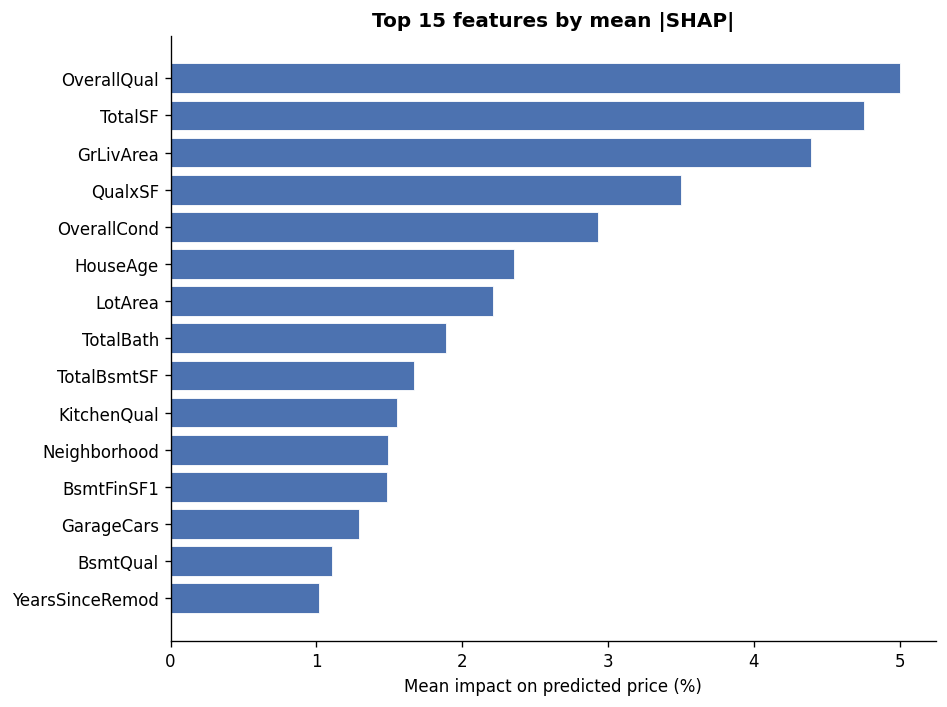

In [10]:
importance = pd.Series(np.abs(expl.values).mean(axis=0), index=expl.feature_names).sort_values()
top = importance.tail(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, (np.exp(top.values) - 1) * 100, color='#4C72B0', edgecolor='white', linewidth=0.5)
ax.set_xlabel('Mean impact on predicted price (%)')
ax.set_title('Top 15 features by mean |SHAP|', fontweight='bold')
plt.tight_layout()
plt.show()

**Quality** (`OverallQual`), **size** (`TotalSF`, `GrLivArea`, and their interaction `QualxSF`), **condition** and **age** dominate, each moving the price by ~2.5–5% on average. Three of the top 6 are features we engineered in step 5 (`TotalSF`, `QualxSF`, `HouseAge`), which confirms that feature engineering paid off.

### 4.2 Direction of the effects
In the *beeswarm* plot each dot is a house: position = contribution to the price, color = value of the feature (red high, blue low).

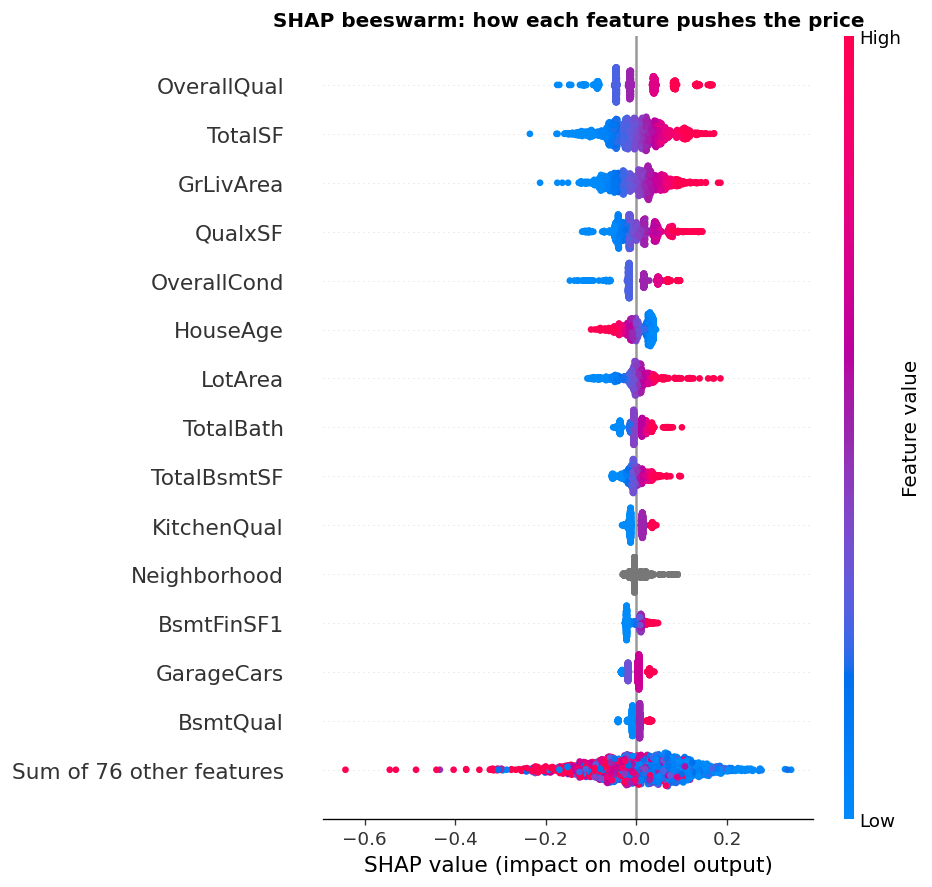

In [11]:
shap.plots.beeswarm(expl, max_display=15, show=False)
plt.title('SHAP beeswarm: how each feature pushes the price', fontweight='bold')
plt.tight_layout()
plt.show()

- High quality, large area, good kitchen, more bathrooms → **higher** price (red dots on the right).
- Higher `HouseAge` → **lower** price (red dots on the left).
- `Neighborhood` appears gray because it's categorical; its effect is shown in the next plot.

### 4.3 Effect of individual features

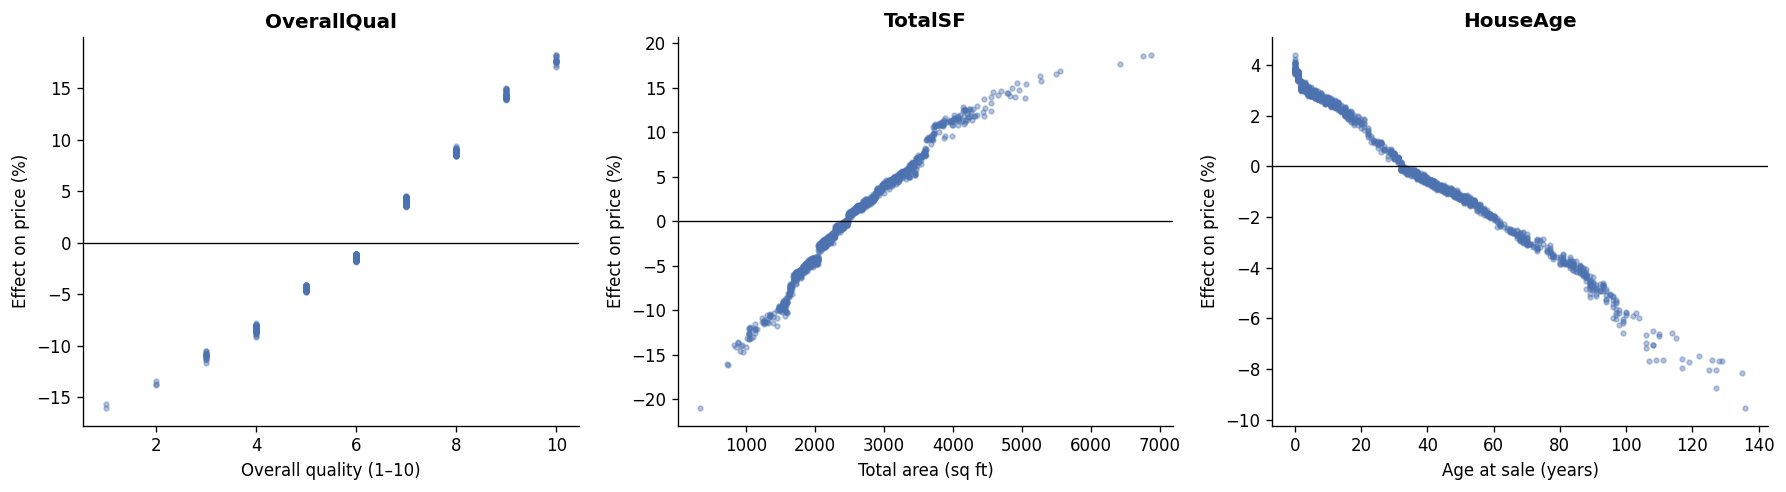

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, feat, xlabel in zip(axes, ['OverallQual', 'TotalSF', 'HouseAge'],
                            ['Overall quality (1–10)', 'Total area (sq ft)', 'Age at sale (years)']):
    i = expl.feature_names.index(feat)
    ax.scatter(expl.display_data[:, i].astype(float), (np.exp(expl.values[:, i]) - 1) * 100,
               s=8, alpha=0.4, color='#4C72B0')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xlabel(xlabel); ax.set_ylabel('Effect on price (%)')
    ax.set_title(feat, fontweight='bold')
plt.tight_layout()
plt.show()

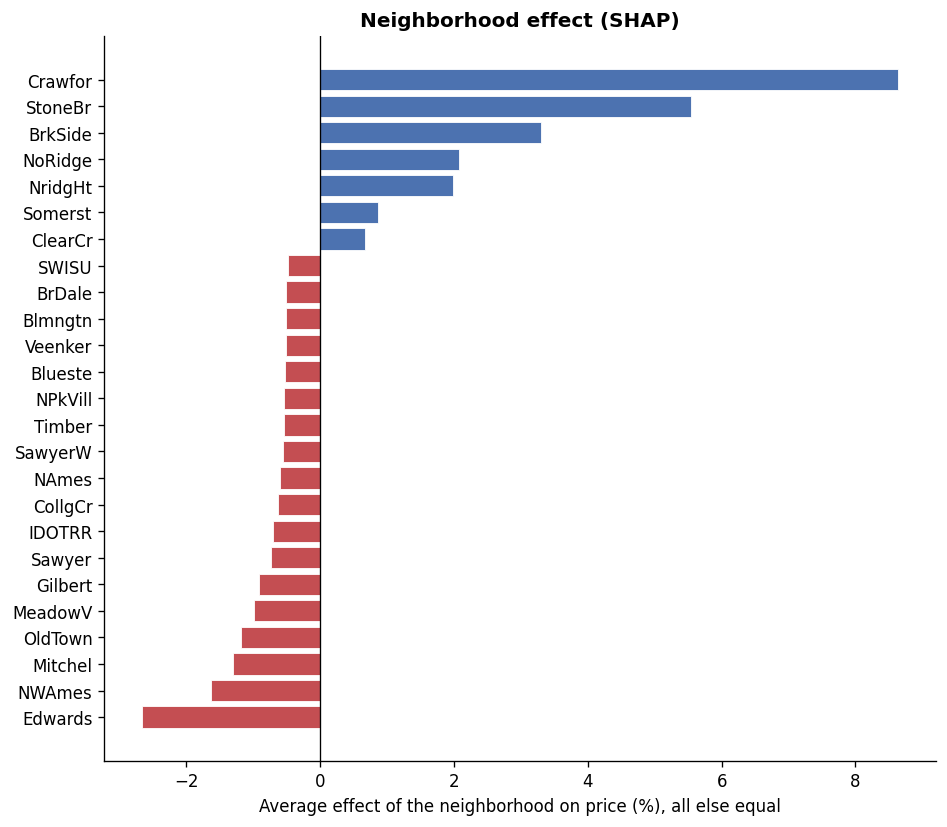

In [13]:
i = expl.feature_names.index('Neighborhood')
nb_effect = (pd.Series(np.exp(expl.values[:, i]) - 1, index=expl.display_data[:, i])
             .groupby(level=0).mean().sort_values() * 100)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(nb_effect.index, nb_effect.values, color=['#C44E52' if v < 0 else '#4C72B0' for v in nb_effect.values],
        edgecolor='white', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Average effect of the neighborhood on price (%), all else equal')
ax.set_title('Neighborhood effect (SHAP)', fontweight='bold')
plt.tight_layout()
plt.show()

- **Quality**: each extra point adds roughly 4–5% to the price, from −16% (quality 1) to +18% (quality 10), compared with an average house.
- **Area**: more space always adds value, but with diminishing returns above ~4,000 sq ft.
- **Age**: a steady decline of roughly 1% per decade, from +4% (new house) to about −8% (130 years old).
- **Neighborhood**, *after* accounting for size and quality, moves the price from about −3% (*Edwards*) to +9% (*Crawford*). This is smaller than the 3.6x difference in median prices seen in the EDA, because part of that difference was really due to bigger, better houses being in the expensive neighborhoods.

### 4.4 Explaining individual predictions
The *waterfall* plot starts from the average prediction and adds each feature's contribution until it reaches the prediction for that specific house.

House Id 393 (cheap): actual $106,500, predicted $104,450


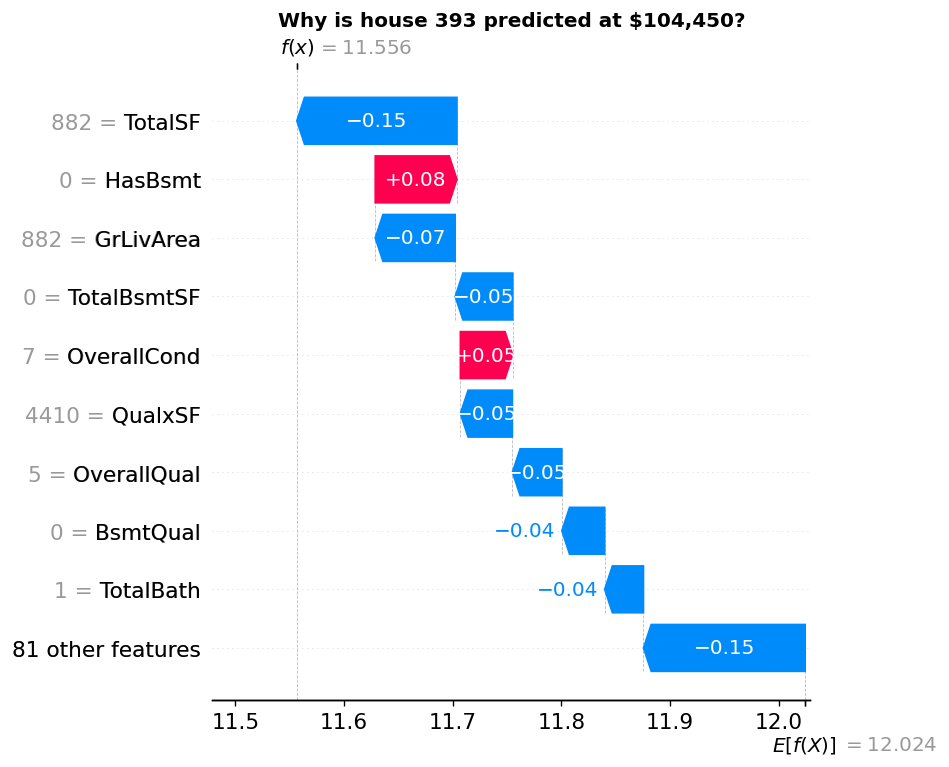

House Id 35 (expensive): actual $277,500, predicted $276,472


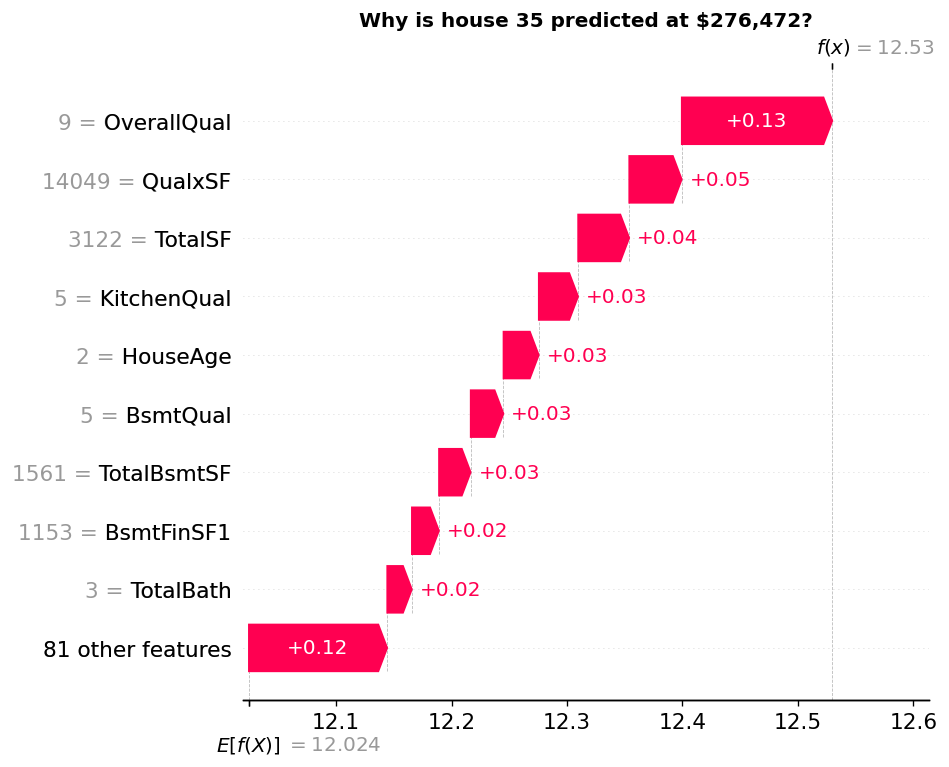

In [14]:
in_sample_pred = np.expm1(final_model.predict(X))
good = (df['pct_error'].abs() < 0.05) & (df['SaleCondition'] == 'Normal')
cheap = df[good]['actual'].sub(df['actual'].quantile(0.10)).abs().idxmin()
expensive = df[good]['actual'].sub(df['actual'].quantile(0.90)).abs().idxmin()

for idx, label in [(cheap, 'cheap'), (expensive, 'expensive')]:
    print(f"House Id {df.loc[idx, 'Id']} ({label}): actual ${df.loc[idx, 'actual']:,.0f}, "
          f"predicted ${in_sample_pred[idx]:,.0f}")
    shap.plots.waterfall(expl[idx], max_display=10, show=False)
    plt.title(f"Why is house {df.loc[idx, 'Id']} predicted at ${in_sample_pred[idx]:,.0f}?", fontweight='bold')
    plt.tight_layout()
    plt.show()

Each bar is a reason: e.g. *"house 393 is predicted cheaper than average mainly because it is small (882 sq ft) and has average quality (5)"*. This is how the model could be explained to a client or a real estate agent.

Note the `HasBsmt = 0 → +0.08` bar on the cheap house: having no basement already penalizes the price through `TotalBsmtSF`, `BsmtQual` and `TotalSF`, and this bar partially *compensates* for that overlap. Correlated features share credit, so their contributions are best read together.

## 5. Conclusions

| Question | Answer |
|---|---|
| How accurate is the model? | R² 0.94; median error ~$8.8k; 77% of houses within ±10% |
| Kaggle (unseen test set) | **0.12392** RMSE (log), close to the CV estimate of 0.107 |
| Where does it fail? | Cheap houses (over-predicted) and non-market sales (family, abnormal, allocation) |
| What drives the price? | Quality, total size, condition, age and location |

**Limitations and possible improvements**
- The data covers one city (Ames, Iowa) in 2006–2010: the model would not transfer directly to another market or time.
- Non-market sales could be modeled separately or removed from training if the goal is to estimate market value.
- Hyperparameters for the boosting models could be tuned more systematically (e.g. Optuna).